In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
ap = pd.read_csv("airports.csv")
flights = pd.read_csv("flights.csv")
airlines = pd.read_csv("airlines.csv")

/var/folders/6k/21d40f610yb11kl9n32yz3h80000gn/T/ipykernel_66678/3201244183.py:7: DtypeWarning: Columns (0: ORIGIN_AIRPORT, 1: DESTINATION_AIRPORT) have mixed types. Specify dtype option on import or set low_memory=False.
  flights = pd.read_csv("flights.csv")


In [116]:
ap.info()
flights.info()
airlines.info()

<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   IATA_CODE  322 non-null    str    
 1   AIRPORT    322 non-null    str    
 2   CITY       322 non-null    str    
 3   STATE      322 non-null    str    
 4   COUNTRY    322 non-null    str    
 5   LATITUDE   319 non-null    float64
 6   LONGITUDE  319 non-null    float64
dtypes: float64(2), str(5)
memory usage: 33.4 KB
<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTU

In [117]:
#dropping cancelled and diverted because they dont contain useful data
flights = flights.drop(['CANCELLED', 'DIVERTED','CANCELLATION_REASON'],axis=1)
#dropping rows where arrival delay is missing
flights.dropna(subset=['ARRIVAL_DELAY'], inplace=True)
#dropping columns which give data after delay takes place
flights = flights.drop(['ARRIVAL_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'WHEELS_ON', 'TAXI_IN',
'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY'],axis=1)

In [118]:
#dropping columns related to departure assuming that we want to predict arrival delay before departure
flights = flights.drop(['DEPARTURE_DELAY','DEPARTURE_TIME', 'TAXI_OUT','WHEELS_OFF'],axis=1)

In [119]:
#dropping useless columns
flights = flights.drop(['YEAR','FLIGHT_NUMBER','TAIL_NUMBER'],axis=1)

In [120]:
#encoding time related columns
def hhmm_to_minutes(t):
    return ((t // 100) * 60 + (t % 100)) % 1440

for col in ['SCHEDULED_DEPARTURE', 'SCHEDULED_ARRIVAL']:
    minutes = hhmm_to_minutes(flights[col])
    flights[col + '_MIN'] = minutes
    angle = 2 * np.pi * minutes / 1440
    flights[col + '_SIN'] = np.sin(angle).astype('float32')
    flights[col + '_COS'] = np.cos(angle).astype('float32')
flights = flights.drop(['SCHEDULED_DEPARTURE', 'SCHEDULED_ARRIVAL'], axis=1)


In [121]:
flights['ORIGIN_AIRPORT'] = flights['ORIGIN_AIRPORT'].astype(str)
flights['DESTINATION_AIRPORT'] = flights['DESTINATION_AIRPORT'].astype(str)
#one hot encoding airlines
flights = pd.get_dummies(flights, columns=['AIRLINE'], drop_first=True)

In [122]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(flights, test_size=0.2, random_state=42)

In [123]:
#frequency encoding the airports
for col in ['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']:
    freq = train[col].value_counts(normalize=True)
    train[col + '_FREQ'] = train[col].map(freq)
    test[col + '_FREQ'] = test[col].map(freq).fillna(0)

train = train.drop(['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT'], axis=1)
test = test.drop(['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT'], axis=1)

In [124]:
X_train, y_train = train.drop('ARRIVAL_DELAY', axis=1), train['ARRIVAL_DELAY']
X_test, y_test = test.drop('ARRIVAL_DELAY', axis=1), test['ARRIVAL_DELAY']

In [125]:
from sklearn.preprocessing import StandardScaler
num_cols = [
    'DISTANCE',                  
    'SCHEDULED_TIME',            
    'SCHEDULED_DEPARTURE_MIN',   
    'SCHEDULED_ARRIVAL_MIN',     
    'ORIGIN_AIRPORT_FREQ',       
    'DESTINATION_AIRPORT_FREQ',
]
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])  
X_test[num_cols] = scaler.transform(X_test[num_cols])

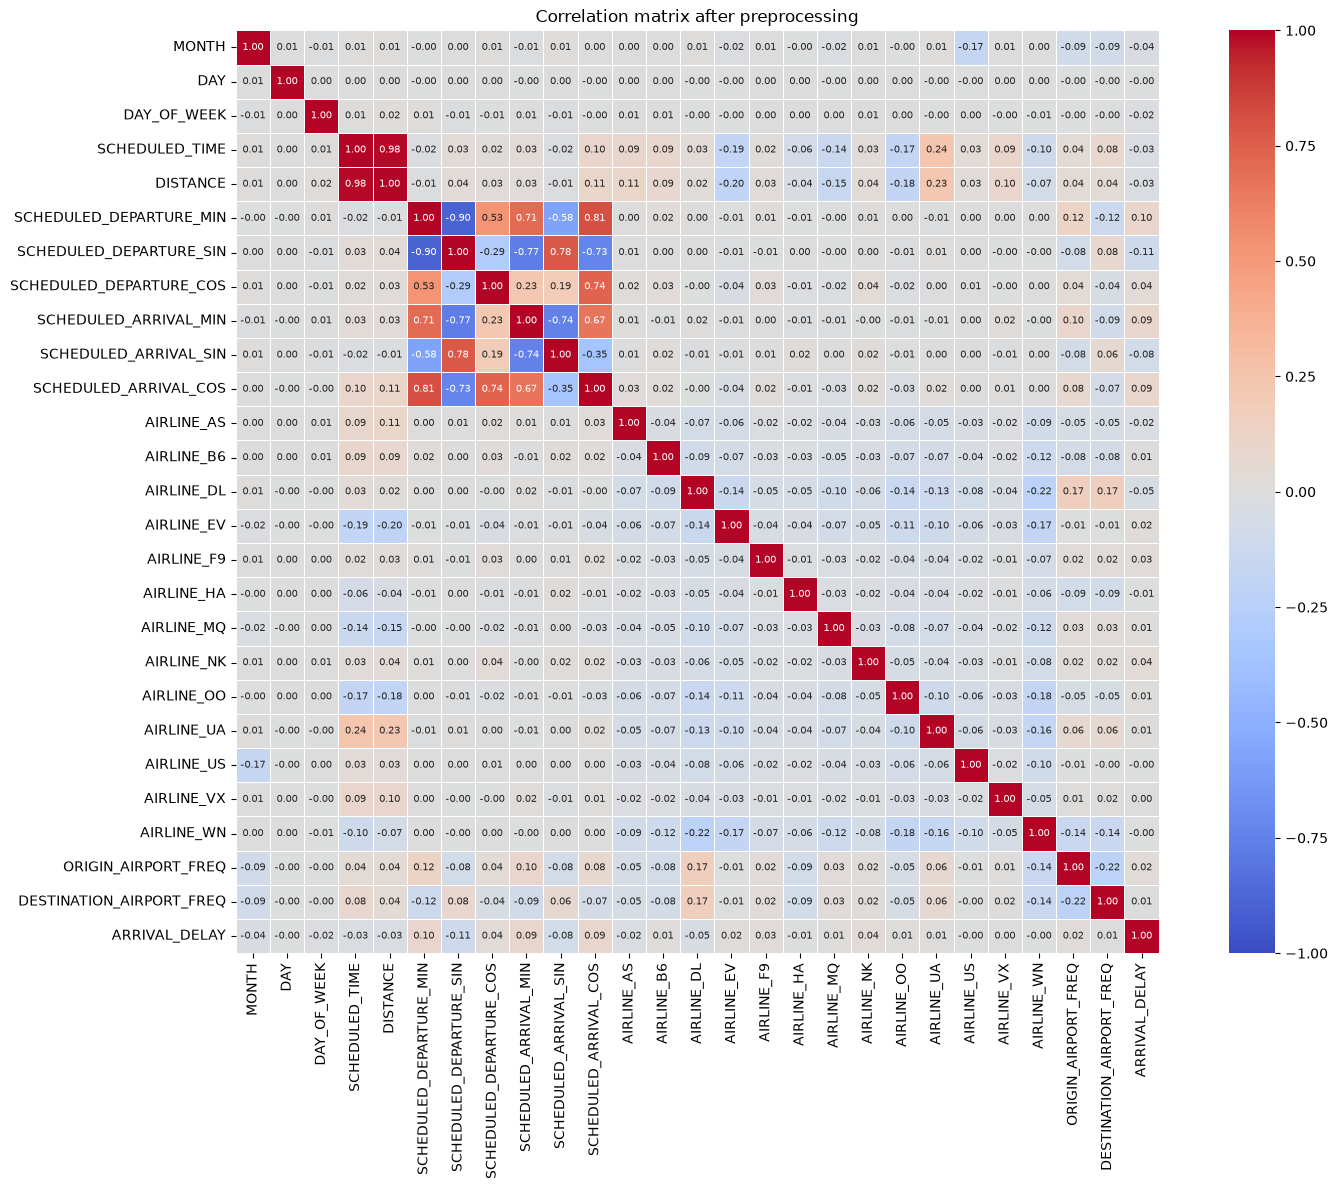

In [126]:
corr_df = pd.concat([X_train, y_train], axis=1).astype('float32')

corr = corr_df.corr()  

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7},
            square=True, linewidths=0.5)
plt.title('Correlation matrix after preprocessing')
plt.tight_layout()
plt.show()

In [127]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 4571206 entries, 3489146 to 1744142
Data columns (total 26 columns):
 #   Column                    Dtype  
---  ------                    -----  
 0   MONTH                     int64  
 1   DAY                       int64  
 2   DAY_OF_WEEK               int64  
 3   SCHEDULED_TIME            float64
 4   DISTANCE                  float64
 5   SCHEDULED_DEPARTURE_MIN   float64
 6   SCHEDULED_DEPARTURE_SIN   float32
 7   SCHEDULED_DEPARTURE_COS   float32
 8   SCHEDULED_ARRIVAL_MIN     float64
 9   SCHEDULED_ARRIVAL_SIN     float32
 10  SCHEDULED_ARRIVAL_COS     float32
 11  AIRLINE_AS                bool   
 12  AIRLINE_B6                bool   
 13  AIRLINE_DL                bool   
 14  AIRLINE_EV                bool   
 15  AIRLINE_F9                bool   
 16  AIRLINE_HA                bool   
 17  AIRLINE_MQ                bool   
 18  AIRLINE_NK                bool   
 19  AIRLINE_OO                bool   
 20  AIRLINE_UA                bool   


In [129]:

X_tr = X_train.to_numpy(dtype=np.float64)
y_tr = y_train.to_numpy(dtype=np.float64)
X_te = X_test.to_numpy(dtype=np.float64)
y_te = y_test.to_numpy(dtype=np.float64)

n, m = X_tr.shape  
print("Training rows:", n, "| features:", m)


Training rows: 4571206 | features: 26


In [130]:
def predict(X, b0, w):
    return b0 + X @ w

def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

def gradients(X, y, y_hat):
    residuals = y - y_hat                      
    d_b0 = -2 * np.mean(residuals)             
    d_w = -2 * (X.T @ residuals) / len(y)      
    return d_b0, d_w

In [133]:
b0 = 0.0                 
w = np.zeros(m)           
learning_rate = 0.001       
max_steps = 1000         
tolerance = 1e-6  
loss_history = []
for step in range(max_steps): 
    y_hat = predict(X_tr, b0, w)
    loss_history.append(mse(y_tr, y_hat))
    d_b0, d_w = gradients(X_tr, y_tr, y_hat)
    step_b0 = d_b0 * learning_rate
    step_w = d_w * learning_rate
    if max(abs(step_b0), np.max(np.abs(step_w))) < tolerance:
        print(f"Converged at step {step}")
        break
    b0 = b0 - step_b0
    w = w - step_w

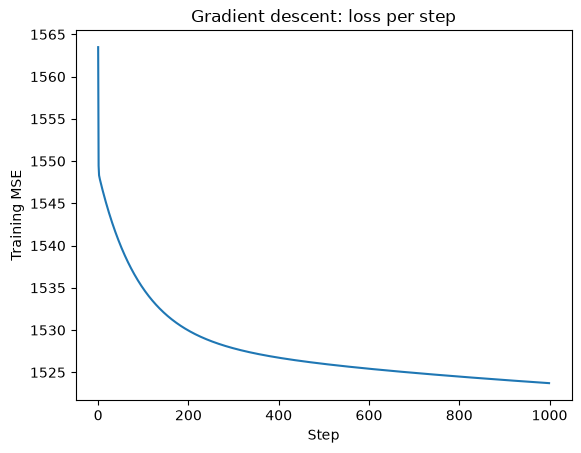

In [134]:
plt.plot(loss_history)
plt.xlabel("Step")
plt.ylabel("Training MSE")
plt.title("Gradient descent")
plt.show()

In [136]:
y_pred = predict(X_te, b0, w)

#root mean squared error
test_mse = mse(y_te, y_pred)
test_rmse = np.sqrt(test_mse)

# R-squared-(SS(mean) - SS(fit)) / SS(mean)
ss_fit = np.sum((y_te - y_pred) ** 2)            
ss_mean = np.sum((y_te - np.mean(y_te)) ** 2)    
r2 = (ss_mean - ss_fit) / ss_mean

print(f"Test RMSE: {test_rmse:.2f} minutes")
print(f"Test R^2:  {r2:.4f}")

Test RMSE: 38.92 minutes
Test R^2:  0.0133
